# Student Performance Classification — CMP6202 D2

**Project:** Predicting student pass/fail outcomes using supervised machine learning.  
**Dataset:** Student Performance Dataset (5,000 records; 16 columns).  
**Intended audience:** Educational data analysts and staff evaluating student-support tools.

This notebook explains the research questions, data checks, exploratory analysis, model development, results and limitations. It compares an early-warning scenario with a separate exam-score scenario. The figures and model comparison table are embedded so they can be viewed directly on GitHub. The experiment code can be rerun with the accompanying CSV to independently check the results.


## 1. Problem and research questions

The target `Pass_Fail` has two categories: **Pass** and **Fail**. We treat this as **binary classification**. The practical question is whether available student information can identify students who may need additional academic support.

**Research questions**

1. How balanced are the pass and fail groups, and why does this matter for evaluation?
2. Are study habits and attendance associated with pass/fail outcomes?
3. How do Logistic Regression, Decision Tree and Random Forest compare when predicting outcomes with and without final examination scores?

**Two prediction settings:** An *early-warning* setting excludes final exam marks, while an *exam-score* setting includes them. The second is easier but cannot realistically be used before the exams.

## 2. Dataset source and limitations

**Source:** [Student Performance Dataset on Kaggle](https://www.kaggle.com/datasets/suvidyasonawane/student-performance-dataset), uploaded by Suvidya Sonawane. The Kaggle dataset is listed under **CC0: Public Domain**.

The supplied CSV contains **5,000 rows**, **16 columns**, **no missing entries** and **no duplicate rows**. A clean file does not guarantee realistic data or unbiased results. The dataset does not provide sufficient evidence here to establish that the records represent real students or that the sample is representative of a particular school.

**Target leakage:** `Final_Percentage` is calculated from `Math_Score`, `Science_Score` and `English_Score`, and `Pass_Fail` follows the 50% threshold. `Performance_Level` also reflects the final outcome. Including `Final_Percentage` or `Performance_Level` as predictors would give the model the answer.

## 3. Reproduce the complete experiment

The following code cells contain the end-to-end implementation in labelled stages. It reads the CSV, generates exploratory plots, creates a stratified training/test split, fits pipelines, uses cross-validation, tunes a Random Forest and writes evaluation outputs into an `outputs` folder.

**Before running:** place `Student_Performance_Dataset.csv` beside this notebook. Install `numpy`, `pandas`, `matplotlib` and `scikit-learn` in your Python environment. In GitHub, saved notebook outputs are visible, but GitHub does not execute Python code.

**Why a stratified split?** Only 265 of the 5,000 records are Fail, so preserving the minority-class proportion in both sets makes comparison fairer. Preprocessing should be fitted using training data only to prevent leakage.

In [1]:
# Imports and libraries

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
# Load dataset and validate data quality
ROOT=Path.cwd()
OUT=ROOT/'outputs';OUT.mkdir(exist_ok=True)
df=pd.read_csv(ROOT/'Student_Performance_Dataset.csv')
assert len(df)>=3000 and df['Pass_Fail'].isin(['Pass','Fail']).all()
assert not df['Student_ID'].duplicated().any()
assert np.allclose(df[['Math_Score','Science_Score','English_Score']].mean(axis=1),df['Final_Percentage'],atol=.01)
assert (np.where(df['Final_Percentage']>=50,'Pass','Fail')==df['Pass_Fail']).all()
summary={'shape':list(df.shape),'missing_cells':int(df.isna().sum().sum()),'duplicate_rows':int(df.duplicated().sum()),'class_counts':df.Pass_Fail.value_counts().to_dict(),'class_percentage':(100*df.Pass_Fail.value_counts(normalize=True)).round(2).to_dict(),'numeric_summary':df.describe().round(2).to_dict()}
(OUT/'dataset_summary.json').write_text(json.dumps(summary,indent=2))

1922

In [3]:
# Exploratory visualisations
plt.figure(figsize=(6,4));df['Pass_Fail'].value_counts().plot.bar();plt.ylabel('Students');plt.title('Pass/fail class distribution');plt.tight_layout();plt.savefig(OUT/'class_distribution.png',dpi=180);plt.close()
fig,ax=plt.subplots(figsize=(7,4));df.boxplot(column='Attendance_Percentage',by='Pass_Fail',ax=ax);fig.suptitle('');ax.set_title('Attendance by outcome');plt.tight_layout();plt.savefig(OUT/'attendance_boxplot.png',dpi=180);plt.close()
fig,ax=plt.subplots(figsize=(7,4));df.groupby('Pass_Fail')['Study_Hours_Per_Day'].hist(alpha=.6,ax=ax,bins=25,legend=True);ax.set_xlabel('Study hours per day');ax.set_ylabel('Students');plt.tight_layout();plt.savefig(OUT/'study_hours_histogram.png',dpi=180);plt.close()
fig,ax=plt.subplots(figsize=(7,5));corr=df.select_dtypes(include='number').corr();im=ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1);ax.set_xticks(range(len(corr)),corr.columns,rotation=80,fontsize=7);ax.set_yticks(range(len(corr)),corr.columns,fontsize=7);fig.colorbar(im,ax=ax);plt.tight_layout();plt.savefig(OUT/'correlation_heatmap.png',dpi=180);plt.close()

In [4]:
# Define target, features and stratified split
# Target 1 denotes minority class (Fail); this makes recall and precision meaningful.
y=(df['Pass_Fail']=='Fail').astype(int)
# 'Early' uses contextual and historical features, not current exam marks.
early=['Age','Gender','Class','Study_Hours_Per_Day','Attendance_Percentage','Parental_Education','Internet_Access','Extracurricular_Activities','Previous_Year_Score']
# Exam-time scenario adds three subject scores, but never derived final percentage/level.
exam=early+['Math_Score','Science_Score','English_Score']
assert not ({'Student_ID','Pass_Fail','Final_Percentage','Performance_Level'} & set(early+exam))
idx_train,idx_test=train_test_split(np.arange(len(df)),test_size=.2,random_state=42,stratify=y)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [5]:
# Train, cross-validate, tune and evaluate models
rows=[]
for scenario,features in [('Early-warning',early),('Exam-score',exam)]:
    X=df[features];Xtr=X.iloc[idx_train];Xte=X.iloc[idx_test];ytr=y.iloc[idx_train];yte=y.iloc[idx_test]
    numeric=X.select_dtypes(include='number').columns.tolist();categorical=[c for c in features if c not in numeric]
    pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric),('category',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),categorical)])
    algorithms={'Majority baseline':DummyClassifier(strategy='most_frequent'),'Logistic regression':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=42),'Decision tree':DecisionTreeClassifier(class_weight='balanced',random_state=42),'Random forest':RandomForestClassifier(n_estimators=150,class_weight='balanced',random_state=42,n_jobs=-1)}
    for name,model in algorithms.items():
        pipe=Pipeline([('preprocess',pre),('model',model)])
        scores=cross_validate(pipe,Xtr,ytr,cv=cv,scoring={'f1':'f1','recall':'recall','balanced_accuracy':'balanced_accuracy'},n_jobs=-1)
        pipe.fit(Xtr,ytr);pred=pipe.predict(Xte)
        prob=pipe.predict_proba(Xte)[:,1] if hasattr(pipe,'predict_proba') else None
        row={'scenario':scenario,'model':name,'cv_f1_mean':np.mean(scores['test_f1']),'cv_f1_sd':np.std(scores['test_f1']),'cv_recall_mean':np.mean(scores['test_recall']),'test_accuracy':accuracy_score(yte,pred),'test_balanced_accuracy':balanced_accuracy_score(yte,pred),'test_precision_fail':precision_score(yte,pred,zero_division=0),'test_recall_fail':recall_score(yte,pred,zero_division=0),'test_f1_fail':f1_score(yte,pred,zero_division=0),'test_roc_auc':roc_auc_score(yte,prob) if prob is not None else np.nan}
        rows.append(row)
        disp=ConfusionMatrixDisplay(confusion_matrix(yte,pred),display_labels=['Pass','Fail']);disp.plot(cmap='Blues',colorbar=False);plt.title(f'{scenario}: {name}');plt.tight_layout();plt.savefig(OUT/(f'confusion_{scenario}_{name}'.replace(' ','_')+'.png'),dpi=160);plt.close()
    # Tune on training set only, evaluate once on untouched test set.
    tuned=GridSearchCV(Pipeline([('preprocess',pre),('model',RandomForestClassifier(class_weight='balanced',random_state=42,n_jobs=-1))]),{'model__n_estimators':[100,200],'model__max_depth':[5,None],'model__min_samples_leaf':[1,5]},scoring='f1',cv=cv,n_jobs=-1,refit=True)
    tuned.fit(Xtr,ytr);pred=tuned.predict(Xte);prob=tuned.predict_proba(Xte)[:,1]
    rows.append({'scenario':scenario,'model':'Tuned random forest','cv_f1_mean':tuned.best_score_,'cv_f1_sd':np.nan,'cv_recall_mean':np.nan,'test_accuracy':accuracy_score(yte,pred),'test_balanced_accuracy':balanced_accuracy_score(yte,pred),'test_precision_fail':precision_score(yte,pred,zero_division=0),'test_recall_fail':recall_score(yte,pred,zero_division=0),'test_f1_fail':f1_score(yte,pred,zero_division=0),'test_roc_auc':roc_auc_score(yte,prob)})
    (OUT/f'tuning_{scenario}.json').write_text(json.dumps({'best_params':tuned.best_params_,'best_cv_f1':tuned.best_score_},indent=2))
    ConfusionMatrixDisplay(confusion_matrix(yte,pred),display_labels=['Pass','Fail']).plot(cmap='Blues',colorbar=False);plt.title(f'{scenario}: tuned random forest');plt.tight_layout();plt.savefig(OUT/f'confusion_{scenario}_Tuned_random_forest.png',dpi=160);plt.close()

In [6]:
# Export and display model comparison
res=pd.DataFrame(rows).round(4);res.to_csv(OUT/'model_results.csv',index=False)
print(res.to_string(index=False));print('\nSaved outputs to',OUT)

     scenario               model  cv_f1_mean  cv_f1_sd  cv_recall_mean  test_accuracy  test_balanced_accuracy  test_precision_fail  test_recall_fail  test_f1_fail  test_roc_auc
Early-warning   Majority baseline      0.0000    0.0000          0.0000          0.947                  0.5000               0.0000            0.0000        0.0000        0.5000
Early-warning Logistic regression      0.0905    0.0083          0.4382          0.493                  0.4206               0.0367            0.3396        0.0663        0.4189
Early-warning       Decision tree      0.0525    0.0161          0.0519          0.901                  0.5024               0.0577            0.0566        0.0571        0.5024
Early-warning       Random forest      0.0000    0.0000          0.0000          0.947                  0.5000               0.0000            0.0000        0.0000        0.4952
Early-warning Tuned random forest      0.0730       NaN             NaN          0.819                  0.4413

## 4. Exploratory Data Analysis (EDA)

EDA helps us understand the dataset **before interpreting the models**. We examine the outcome balance, attendance, study time and correlations. Visual relationships do not establish causation: a variable associated with failure does not necessarily cause it.

### 4.1 Target balance: how many students pass or fail?

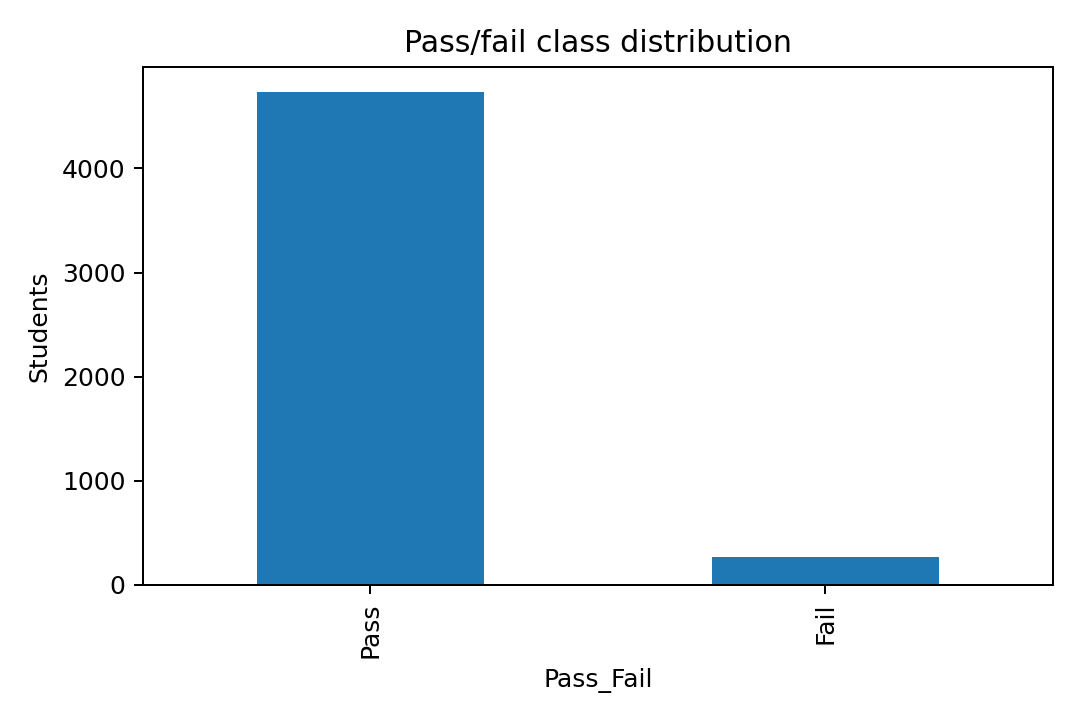

**What this shows:** 4,735 students (94.7%) are labelled Pass and 265 (5.3%) Fail. The dataset is **strongly imbalanced**.

**Why it matters:** A model that predicts Pass for everyone would achieve **94.7% accuracy** while detecting **zero** failing students. Therefore, we need Fail-class recall, precision, F1 and balanced accuracy, not just overall accuracy.

### 4.2 Attendance by pass/fail outcome

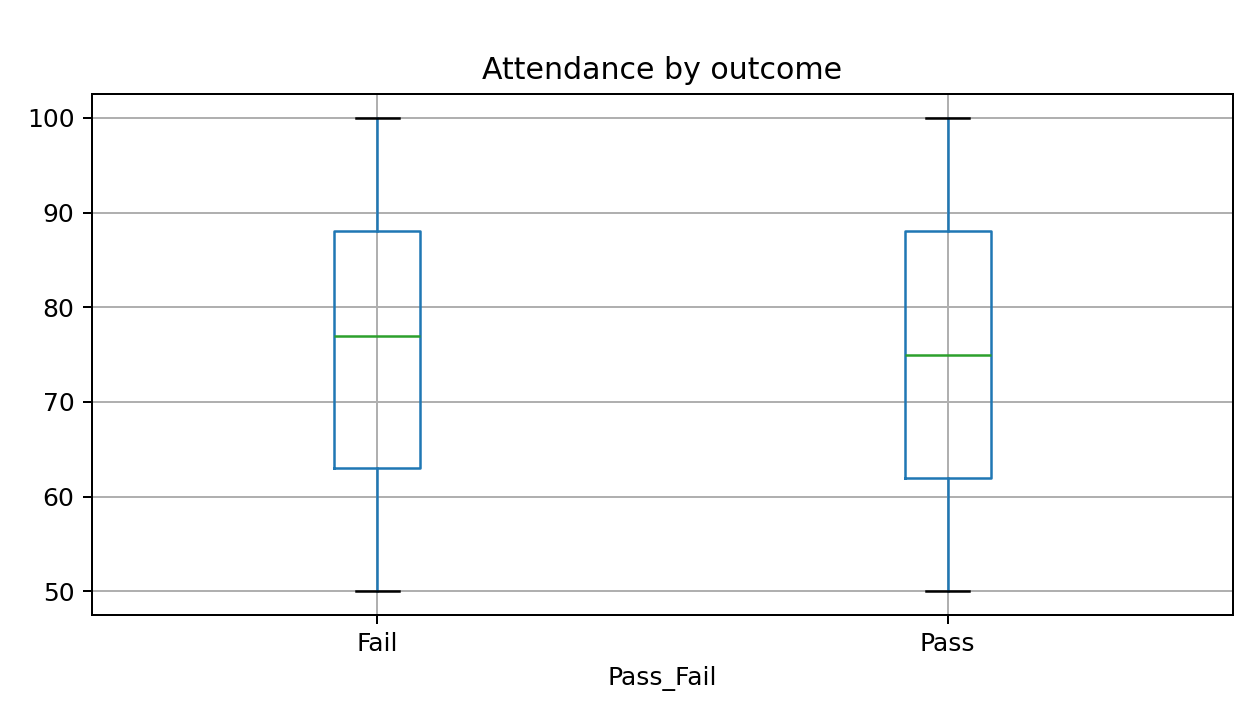

**How to read this:** The box represents the middle half of attendance values, the line inside is the median, and points beyond the whiskers may indicate unusual observations. Compare the two boxes to see whether their typical attendance levels and spreads differ.

**Interpretation:** Any overlap means attendance alone cannot perfectly distinguish Pass from Fail. This chart is exploratory: a visual difference should not be described as proof that attendance causes academic performance.

### 4.3 Study-hours distribution

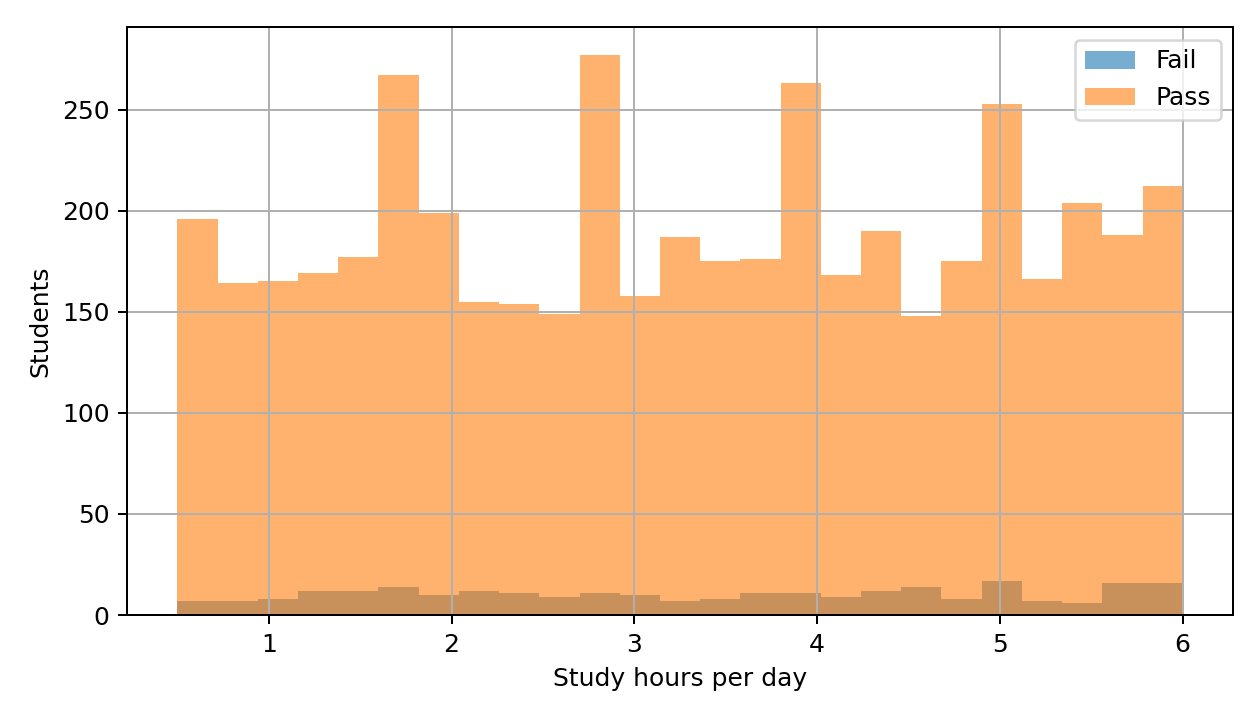

**What this shows:** The overlapping histograms show how frequently different study-hour values occur in the Pass and Fail groups. Look for concentration, skew, unusually high or low values, and whether the range is plausible.

**Why it matters:** Study hours might be a useful predictor, but its distribution alone does not establish how strongly it predicts the outcome. Because the groups differ greatly in size, raw histogram counts should not be interpreted as directly comparable rates.

### 4.4 Correlations between numerical features

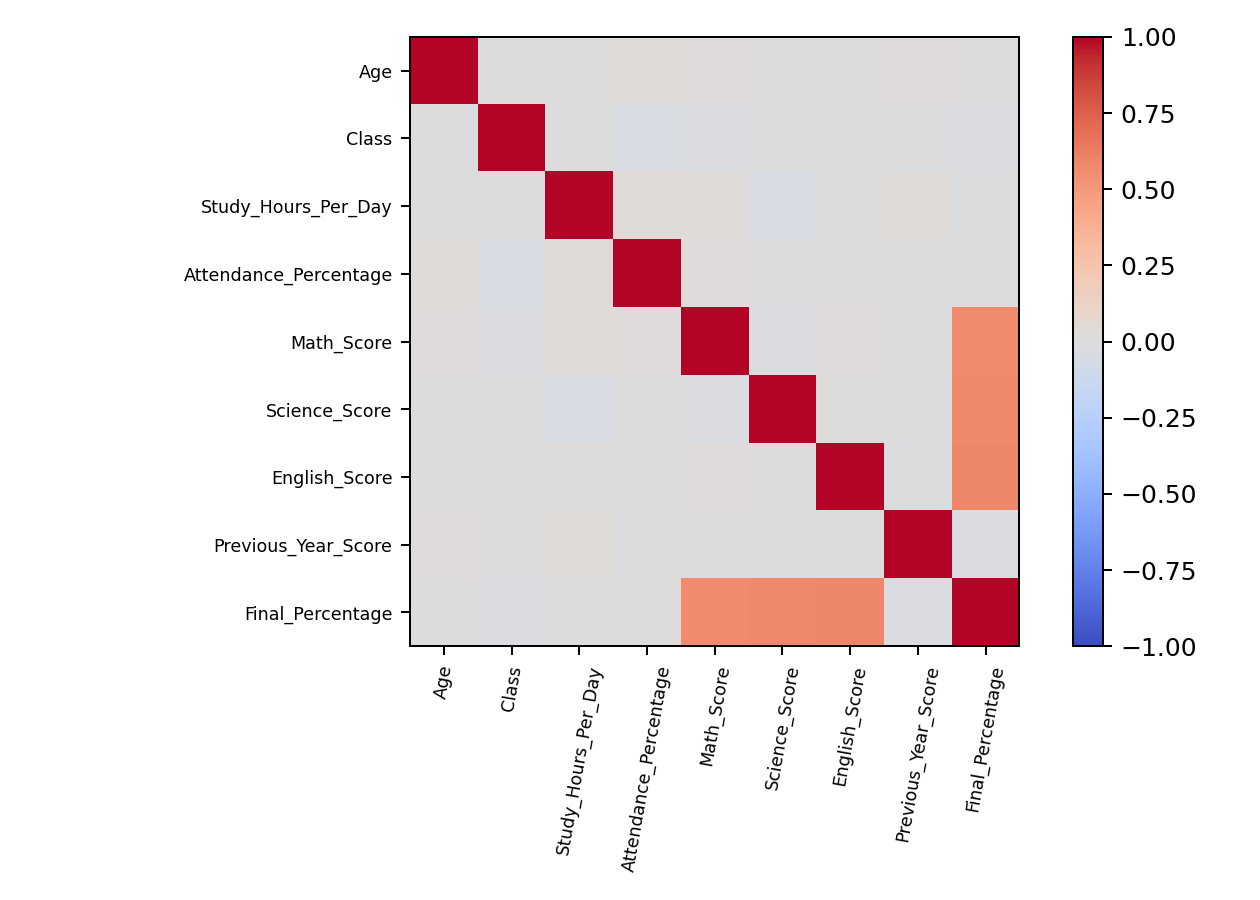

**How to read this:** Correlations close to +1 indicate a strong positive linear relationship, values close to −1 indicate a strong negative linear relationship, and values around zero indicate little *linear* relationship.

**Important limitation:** Correlation is not causation. Also, the three subject marks and `Final_Percentage` are mathematically related, so high correlations involving them may reflect the way the dataset was constructed rather than a new discovery.

### 4.5 Data quality and feature checks

The initial checks found no null entries or duplicated rows. Nevertheless, good preprocessing still matters: categorical columns must be encoded and numerical variables scaled where the algorithm benefits.

**Feature selection:** Remove identifiers such as `Student_ID`, and exclude `Final_Percentage` and `Performance_Level` from predictors. Consider whether subject scores would be available at the moment a real prediction is needed. The early-warning and exam-score settings deliberately answer different questions.

**Further validation:** A future study could examine unusual values, compare group-wise medians and test whether results generalise to independently collected student records.

## 5. Model development

### 5.1 Why these algorithms?

- **Dummy majority classifier:** A baseline showing what happens if we always predict the common class.
- **Logistic Regression:** A simple interpretable linear baseline for binary classification; numerical scaling helps it.
- **Decision Tree:** Captures nonlinear rules and interactions, but may overfit without restrictions.
- **Random Forest:** Combines many trees to reduce variance and model more complex patterns, at the cost of interpretability.

The code uses preprocessing pipelines so imputation, scaling and categorical encoding are learned from training folds, not the held-out test data.

### 5.2 Train/test split, cross-validation and tuning

A stratified **80/20** split gives approximately 4,000 training and 1,000 test records. Cross-validation assesses variability across training folds; grid search compares alternative hyperparameter settings without selecting them based on the final test set. The test set should be reserved for the final unbiased comparison.

## 6. Model evaluation: what do the scores mean?

- **Accuracy:** Fraction of all predictions that are correct. Misleading on heavily imbalanced data.
- **Fail precision:** Of the students predicted to fail, how many actually failed?
- **Fail recall:** Of the students who actually failed, how many did the model identify? Important for early intervention.
- **Fail F1:** Harmonic mean of Fail precision and Fail recall; penalises a model that performs poorly on either.
- **Balanced accuracy:** Average recall across both classes, preventing the majority class from dominating the headline score.
- **ROC AUC:** How well a model ranks positive and negative cases across thresholds; interpret alongside precision/recall when failures are rare.

In this notebook **Fail** is the minority outcome of interest. A useful early-warning system should identify failing students without overwhelming staff with false alerts.

### 6.1 Saved model comparison

The following results are recorded from the experiment. The code above generates a fresh `outputs/model_results.csv` when run. Metrics are rounded to three decimal places for readability; `nan` means a cross-validation statistic was not recorded for the tuned model.

| scenario      | model               |   cv_f1_mean |   cv_f1_sd |   cv_recall_mean |   test_accuracy |   test_balanced_accuracy |   test_precision_fail |   test_recall_fail |   test_f1_fail |   test_roc_auc |
|:--------------|:--------------------|-------------:|-----------:|-----------------:|----------------:|-------------------------:|----------------------:|-------------------:|---------------:|---------------:|
| Early-warning | Majority baseline   |        0     |      0     |            0     |           0.947 |                    0.5   |                 0     |              0     |          0     |          0.5   |
| Early-warning | Logistic regression |        0.09  |      0.008 |            0.438 |           0.493 |                    0.421 |                 0.037 |              0.34  |          0.066 |          0.419 |
| Early-warning | Decision tree       |        0.052 |      0.016 |            0.052 |           0.901 |                    0.502 |                 0.058 |              0.057 |          0.057 |          0.502 |
| Early-warning | Random forest       |        0     |      0     |            0     |           0.947 |                    0.5   |                 0     |              0     |          0     |          0.495 |
| Early-warning | Tuned random forest |        0.073 |    nan     |          nan     |           0.819 |                    0.441 |                 0.008 |              0.019 |          0.011 |          0.431 |
| Exam-score    | Majority baseline   |        0     |      0     |            0     |           0.947 |                    0.5   |                 0     |              0     |          0     |          0.5   |
| Exam-score    | Logistic regression |        0.82  |      0.051 |            1     |           0.978 |                    0.988 |                 0.707 |              1     |          0.828 |          1     |
| Exam-score    | Decision tree       |        0.846 |      0.045 |            0.83  |           0.98  |                    0.892 |                 0.824 |              0.792 |          0.808 |          0.892 |
| Exam-score    | Random forest       |        0.728 |      0.052 |            0.589 |           0.975 |                    0.773 |                 0.967 |              0.547 |          0.699 |          0.997 |
| Exam-score    | Tuned random forest |        0.838 |    nan     |          nan     |           0.984 |                    0.965 |                 0.794 |              0.943 |          0.862 |          0.996 |

### 6.2 Reading the comparison table

**Key finding:** The majority-class baseline reaches 94.7% accuracy but has **Fail F1 = 0**. The early-warning Random Forest also reached 94.7% accuracy with **Fail F1 = 0** in the recorded test run. This is not evidence of an effective early-warning system.

The early-warning Logistic Regression recorded approximately **49.3% accuracy** and **0.066 Fail F1**. The exam-score Logistic Regression achieved approximately **97.8% accuracy** and **0.828 Fail F1**; the tuned exam-score Random Forest reached approximately **98.4% accuracy** and **0.862 Fail F1**.

**Interpretation:** High exam-score performance is expected because the label is defined from exam performance. These results should not be presented as proof that the model can predict failure early in the academic year.

### 6.3 Confusion matrix: early-warning Random Forest

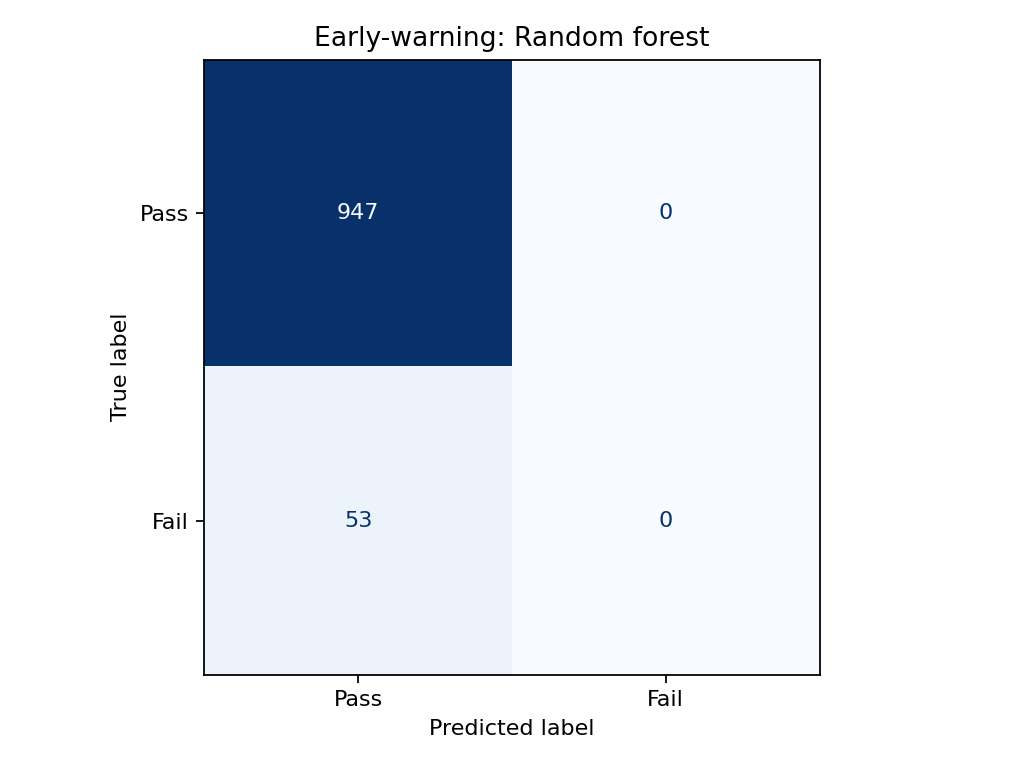

**How to read this:** A confusion matrix counts correct Pass predictions, correct Fail predictions and the two types of mistakes. Check the axis labels to identify which direction corresponds to actual versus predicted classes.

**What this shows:** The recorded early-warning Random Forest failed to detect any Fail cases, despite high overall accuracy. This is a major practical weakness because the system would miss the very students it is intended to flag. The model should not be deployed for intervention based on these results.

### 6.4 Confusion matrix: tuned exam-score Random Forest

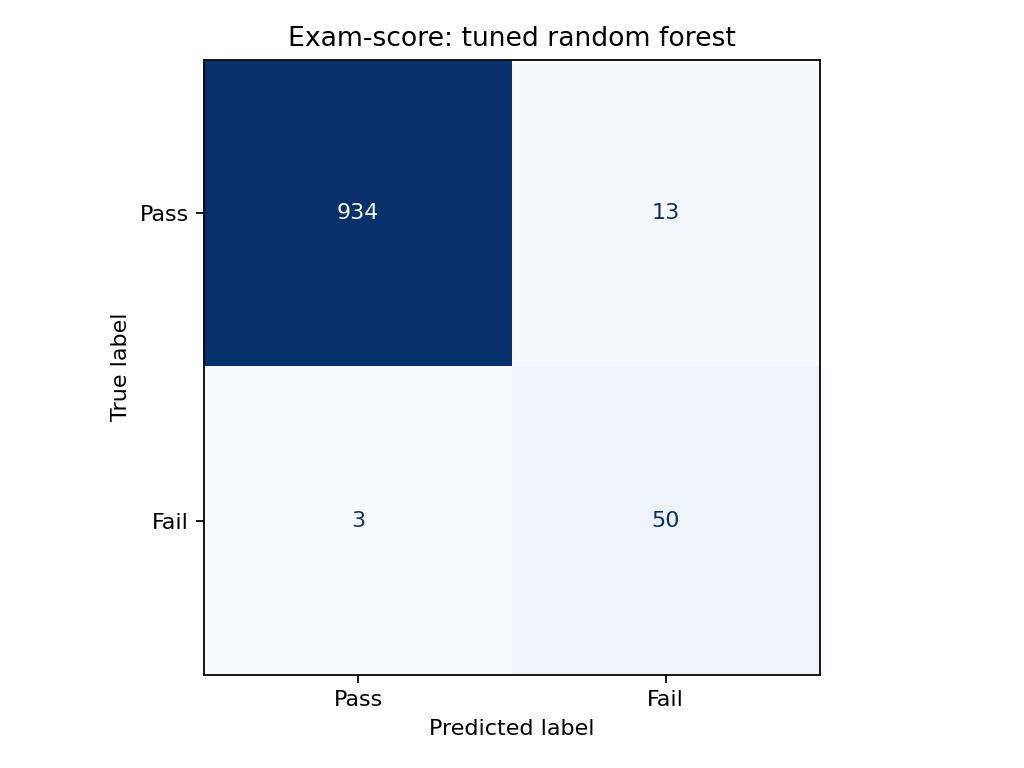

**What this shows:** The tuned exam-score model identifies considerably more failing students and achieves higher Fail F1 than the early-warning models. Inspect the false-positive and false-negative cells to understand remaining errors.

**Critical limitation:** This model uses final subject marks closely related to the outcome definition. It is useful as a comparison of modelling scenarios, **not** as evidence of reliable advance prediction.

## 7. Critical discussion and improvements

**Class imbalance:** With only 5.3% Fail records, prioritise minority-class recall/F1, balanced accuracy and a precision–recall curve. Class weighting or resampling **within training folds only** could be explored, but improvements must be checked on untouched test data.

**Leakage and timing:** Define exactly when a prediction would be made. Exclude any variables unavailable at that time. A model with exam scores answers a different and less useful operational question from an early-warning model.

**Dataset quality:** No missing values does not prove representativeness. Verify whether the dataset is synthetic, how outcomes were generated and whether it reflects a real student population.

**Evaluation improvements:** Repeat experiments across several random seeds, compare threshold settings, report uncertainty, inspect feature importance cautiously and evaluate on an independent dataset if one becomes available.

**Responsible use:** Incorrect risk labels could affect students unfairly. Any real deployment would require privacy safeguards, fairness assessment and human oversight.

## 8. Conclusion

The analysis demonstrates why **accuracy alone is insufficient** for imbalanced student-outcome classification. Early-warning models did not reliably identify the small Fail group, whereas models using final subject marks performed much better but depended on information directly linked to the outcome.

The main lesson is methodological: evaluate the minority class, avoid target leakage and match predictors to the real decision point. Further work should use genuinely pre-exam features and validate results on independently collected data.

## 9. Reproducibility, references and responsible use

**Reproducibility:** Keep `Student_Performance_Dataset.csv` in the same folder as `classification.ipynb`. Run the notebook with Python and the libraries `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The experiment saves summary statistics, figures, model comparison metrics and tuning details in the `outputs` folder. GitHub displays the embedded figures but does not run notebook code.

**Interpretation and responsible use:** The results describe this dataset and the tested feature sets, not a validated intervention system. In particular, the exam-score models use marks that determine the target label; their strong performance is not evidence of advance prediction. The small Fail class, uncertain data provenance and lack of external validation limit real-world conclusions.

**Dataset reference (Harvard style):** Sonawane, S. (n.d.) *Student Performance Dataset*. Kaggle. Available at: https://www.kaggle.com/datasets/suvidyasonawane/student-performance-dataset (Accessed: 19 November 2026).

**Supporting software reference:** Pedregosa, F. *et al.* (2011) ‘Scikit-learn: Machine learning in Python’, *Journal of Machine Learning Research*, 12, pp. 2825–2830. Available at: https://jmlr.org/papers/v12/pedregosa11a.html.
